In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
import warnings
warnings.filterwarnings('ignore')


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print(f"TensorFlow версия: {tf.__version__}")
print(f"Доступные GPU: {tf.config.list_physical_devices('GPU')}")

TensorFlow версия: 2.20.0
Доступные GPU: []


In [2]:
current_dir = os.getcwd()
possible_paths = [
    './Dataset',  
    'Dataset',
    os.path.join(current_dir, 'Dataset'),
    os.path.join(current_dir, '..', 'Dataset'),
    './vehicle-type-recognition',
    'vehicle-type-recognition',
    '/kaggle/input/vehicle-type-recognition',
]

In [3]:
DATA_PATH = None
print("Поиск датасета...")
print(f"Текущая рабочая директория: {current_dir}\n")

for path in possible_paths:
    abs_path = os.path.abspath(path)
    if os.path.exists(path):
        subdirs = [d for d in os.listdir(path) 
                  if os.path.isdir(os.path.join(path, d)) and not d.startswith('.')]
        if subdirs:
            DATA_PATH = path
            print(f"Датасет найден: {abs_path}")
            print(f"Найденные папки классов: {subdirs}")
            break

if DATA_PATH is None:
    print("ОШИБКА: Датасет не найден автоматически!")
    print("\nПроверенные пути:")
    for p in possible_paths:
        print(f"  {os.path.abspath(p)} - {'существует' if os.path.exists(p) else 'не найден'}")
    
    print("\nПожалуйста, укажите путь к датасету вручную:")
    print("Раскомментируйте и измените строку ниже:")
    print("# DATA_PATH = r'C:\\Users\\YourName\\путь\\к\\Dataset'")
    print("\nИли поместите папку Dataset в ту же директорию, где находится этот notebook")
    raise FileNotFoundError("Датасет не найден. Укажите правильный путь к папке Dataset")

print(f"Используется путь к датасету: {DATA_PATH}")


Поиск датасета...
Текущая рабочая директория: C:\Users\user

Датасет найден: C:\Users\user\Dataset
Найденные папки классов: ['Bus', 'Car', 'motorcycle', 'Truck']
Используется путь к датасету: ./Dataset


In [4]:
IMG_SIZE = (128, 128)  
BATCH_SIZE = 32 
EPOCHS = 30 
NUM_CLASSES = None  



print("\nСтруктура датасета:")
if os.path.exists(DATA_PATH):
    for root, dirs, files in os.walk(DATA_PATH):
        level = root.replace(DATA_PATH, '').count(os.sep)
        indent = ' ' * 2 * level
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 2 * (level + 1)
        for file in files[:3]:
            print(f'{subindent}{file}')
        if len(files) > 3:
            print(f'{subindent}... и еще {len(files)-3} файлов')
        if level > 2: 
            break

train_path = os.path.join(DATA_PATH, 'train')
test_path = os.path.join(DATA_PATH, 'test')

if not os.path.exists(train_path):
    print(f"\nВНИМАНИЕ: Папка 'train' не найдена по пути: {train_path}")
    print("Возможно, структура датасета отличается.")
    print("Проверьте содержимое папки датасета.")
    
if not os.path.exists(test_path):
    print(f"\nВНИМАНИЕ: Папка 'test' не найдена по пути: {test_path}")
    print("Датасет может содержать только train данные.")
    print("В этом случае мы разделим train на train/val/test.")


Структура датасета:
Dataset/
  .ipynb_checkpoints/
  Bus/
    Image_1.jpg
    Image_10.jpg
    Image_100.jpg
    ... и еще 97 файлов
  Car/
    Image_1.jpg
    Image_10.jpeg
    Image_100.jpg
    ... и еще 97 файлов
    .ipynb_checkpoints/
      Image_2-checkpoint.jpg
  motorcycle/
    Image_1.jpeg
    Image_10.jpg
    Image_100.jpg
    ... и еще 97 файлов
  Truck/
    Image_1.jpg
    Image_10.jpg
    Image_100.jpg
    ... и еще 97 файлов

ВНИМАНИЕ: Папка 'train' не найдена по пути: ./Dataset\train
Возможно, структура датасета отличается.
Проверьте содержимое папки датасета.

ВНИМАНИЕ: Папка 'test' не найдена по пути: ./Dataset\test
Датасет может содержать только train данные.
В этом случае мы разделим train на train/val/test.


In [5]:
def is_valid_class_folder(folder_name):
    """Проверка, является ли папка валидным классом"""
    invalid_folders = ['.ipynb_checkpoints', '__pycache__', '.git', 'Thumbs.db', '.DS_Store']
    return folder_name not in invalid_folders and not folder_name.startswith('.')

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  
)

In [7]:
test_datagen = ImageDataGenerator(rescale=1./255)

In [8]:
try:
    train_generator = train_datagen.flow_from_directory(
        os.path.join(DATA_PATH, 'train'),
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset='training',
        shuffle=True
    )

    validation_generator = train_datagen.flow_from_directory(
        os.path.join(DATA_PATH, 'train'),
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset='validation',
        shuffle=False
    )

    test_generator = test_datagen.flow_from_directory(
        os.path.join(DATA_PATH, 'test'),
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )
    
except FileNotFoundError:
    print("\nСтандартная структура train/test не найдена.")
    print("Попытка загрузки данных из корневой директории...\n")
    

    all_folders = [f for f in os.listdir(DATA_PATH) 
                   if os.path.isdir(os.path.join(DATA_PATH, f))]
    valid_classes = [f for f in all_folders if is_valid_class_folder(f)]
    
    print(f"Найденные папки: {all_folders}")
    print(f"Валидные классы транспорта: {valid_classes}")
    
    if not valid_classes:
        raise ValueError("Не найдено ни одного валидного класса!")
    

    train_datagen_full = ImageDataGenerator(
        rescale=1./255,
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest',
        validation_split=0.3
    )
    
    train_generator = train_datagen_full.flow_from_directory(
        DATA_PATH,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset='training',
        shuffle=True,
        classes=valid_classes 
    )
    
    validation_generator = train_datagen_full.flow_from_directory(
        DATA_PATH,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset='validation',
        shuffle=False,
        classes=valid_classes  
    )
    

    test_generator = validation_generator


Стандартная структура train/test не найдена.
Попытка загрузки данных из корневой директории...

Найденные папки: ['.ipynb_checkpoints', 'Bus', 'Car', 'motorcycle', 'Truck']
Валидные классы транспорта: ['Bus', 'Car', 'motorcycle', 'Truck']
Found 281 images belonging to 4 classes.
Found 120 images belonging to 4 classes.


In [9]:
NUM_CLASSES = len(train_generator.class_indices)
NUM_CLASSES = len(train_generator.class_indices)

In [10]:
class_names = list(train_generator.class_indices.keys())
print(class_names)

['Bus', 'Car', 'motorcycle', 'Truck']


In [11]:
    if BATCH_SIZE > train_generator.samples // 4:
        old_batch = BATCH_SIZE
        BATCH_SIZE = max(4, train_generator.samples // 4)
        print(f"Адаптация BATCH_SIZE: {old_batch} -> {BATCH_SIZE} (из-за малого размера датасета)\n")
        
        train_generator.batch_size = BATCH_SIZE
        validation_generator.batch_size = BATCH_SIZE
        test_generator.batch_size = BATCH_SIZE
    
    print("Рекомендация: Для маленького датасета используйте только Transfer Learning модели.")
    print("Можете вручную изменить флаги RUN_XXX в разделе 'ЭКСПЕРИМЕНТЫ С МОДЕЛЯМИ'\n")

Рекомендация: Для маленького датасета используйте только Transfer Learning модели.
Можете вручную изменить флаги RUN_XXX в разделе 'ЭКСПЕРИМЕНТЫ С МОДЕЛЯМИ'




Примеры изображений из тренировочной выборки:


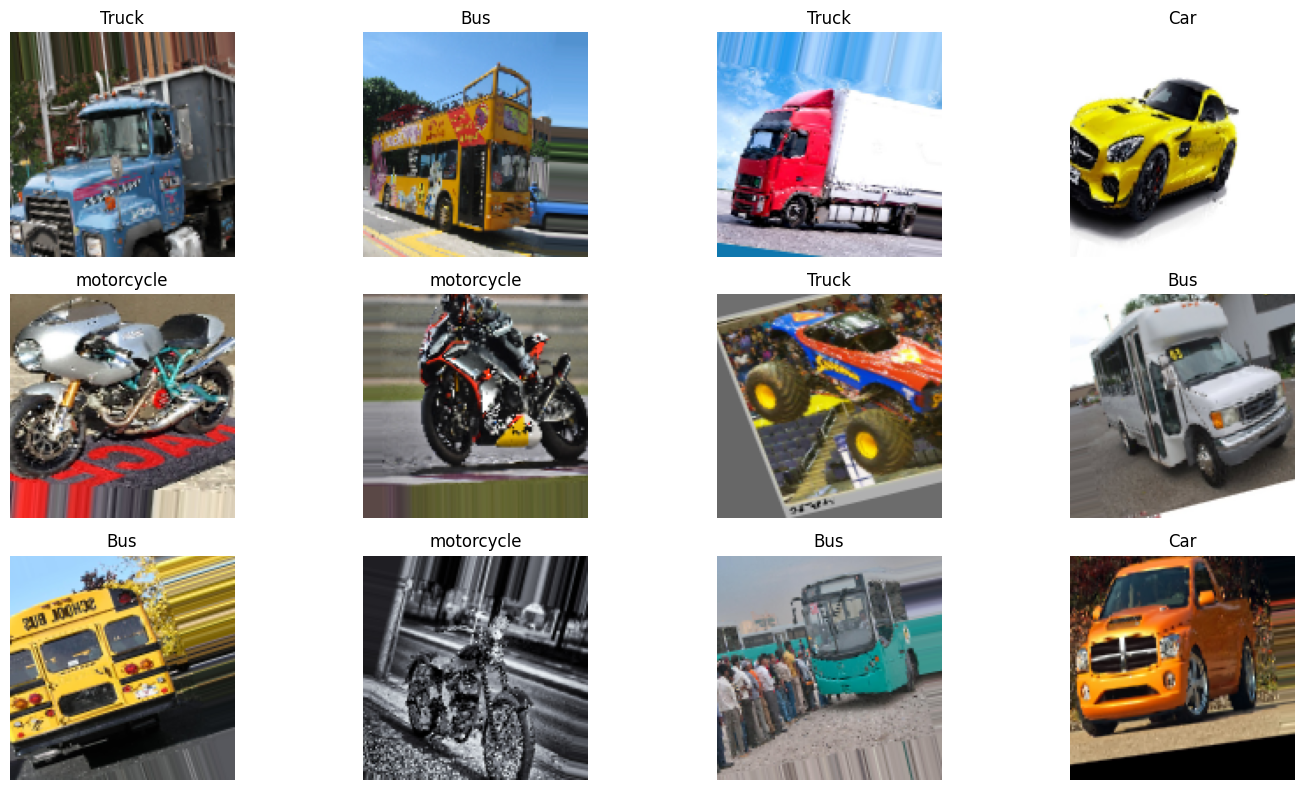

In [12]:
def show_batch(generator):
    batch = next(generator)
    images = batch[0]
    labels = batch[1]
    
    plt.figure(figsize=(15, 8))
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i+1)
        plt.imshow(images[i])
        class_idx = np.argmax(labels[i])
        plt.title(f"{class_names[class_idx]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

print("\nПримеры изображений из тренировочной выборки:")
show_batch(train_generator)

In [13]:
def create_simple_cnn(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

In [14]:
def create_deep_cnn(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), padding='same', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

In [15]:
def create_transfer_learning_model(input_shape, num_classes, trainable_layers=20):
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    

    base_model.trainable = True
    for layer in base_model.layers[:-trainable_layers]:
        layer.trainable = False
    
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

In [16]:
def create_advanced_cnn(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)
    

    x = layers.Conv2D(64, (3, 3), padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)
    

    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)
    

    x = layers.Conv2D(256, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(256, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.4)(x)
    

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

In [17]:
def train_and_evaluate(model, model_name, optimizer='adam', learning_rate=0.001):
    print(f"\n{'='*60}")
    print(f"Обучение модели: {model_name}")
    print(f"{'='*60}\n")
    
    if optimizer == 'adam':
        opt = keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer == 'sgd':
        opt = keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    elif optimizer == 'rmsprop':
        opt = keras.optimizers.RMSprop(learning_rate=learning_rate)
    
    model.compile(
        optimizer=opt,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=7,  
        restore_best_weights=True,
        verbose=1
    )
    
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3, 
        min_lr=1e-7,
        verbose=1
    )
    

    history = model.fit(
        train_generator,
        epochs=EPOCHS,
        validation_data=validation_generator,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
    

    print("\nОценка на тестовой выборке:")
    test_loss, test_accuracy = model.evaluate(test_generator)
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    

    plot_training_history(history, model_name)
    

    plot_confusion_matrix(model, test_generator, class_names, model_name)
    
    return history, test_accuracy

In [18]:
def plot_training_history(history, model_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    

    ax1.plot(history.history['accuracy'], label='Train Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
    ax1.set_title(f'{model_name} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True)
    

    ax2.plot(history.history['loss'], label='Train Loss')
    ax2.plot(history.history['val_loss'], label='Val Loss')
    ax2.set_title(f'{model_name} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

In [19]:
def plot_confusion_matrix(model, test_gen, class_names, model_name):
    test_gen.reset()
    predictions = model.predict(test_gen, verbose=1)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_gen.classes
    
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()
    
    print(f"\nClassification Report для {model_name}:")
    print(classification_report(y_true, y_pred, target_names=class_names))


In [20]:
RUN_SIMPLE_CNN = True
RUN_DEEP_CNN = False
RUN_TRANSFER_LEARNING = True 
RUN_ADVANCED_CNN = False
RUN_DEEP_CNN_SGD = False 


Используется 4 классов: ['Bus', 'Car', 'motorcycle', 'Truck']
Входной размер изображения: (128, 128, 3)


ЭКСПЕРИМЕНТ 1: Простая CNN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Обучение модели: Simple CNN

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.2456 - loss: 1.5233 - val_accuracy: 0.2417 - val_loss: 1.3849 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.2669 - loss: 1.3850 - val_accuracy: 0.2500 - val_loss: 1.3718 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.2847 - loss: 1.3809 - val_accuracy: 0.3083 - val_loss: 1.3608 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.3025 - loss: 1.3670 - val_accuracy: 0.3750 - val_loss: 1.3293 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.3452 - loss: 1.3508 - val_accuracy: 0.4417 - val_loss: 1.3220 - learning_rate: 0.0010
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.4093 - loss: 1.2595 - val_accuracy: 0.5167 - val_loss: 1.2524 - learning_rate: 0.0010
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.3986 - loss: 1.2646 

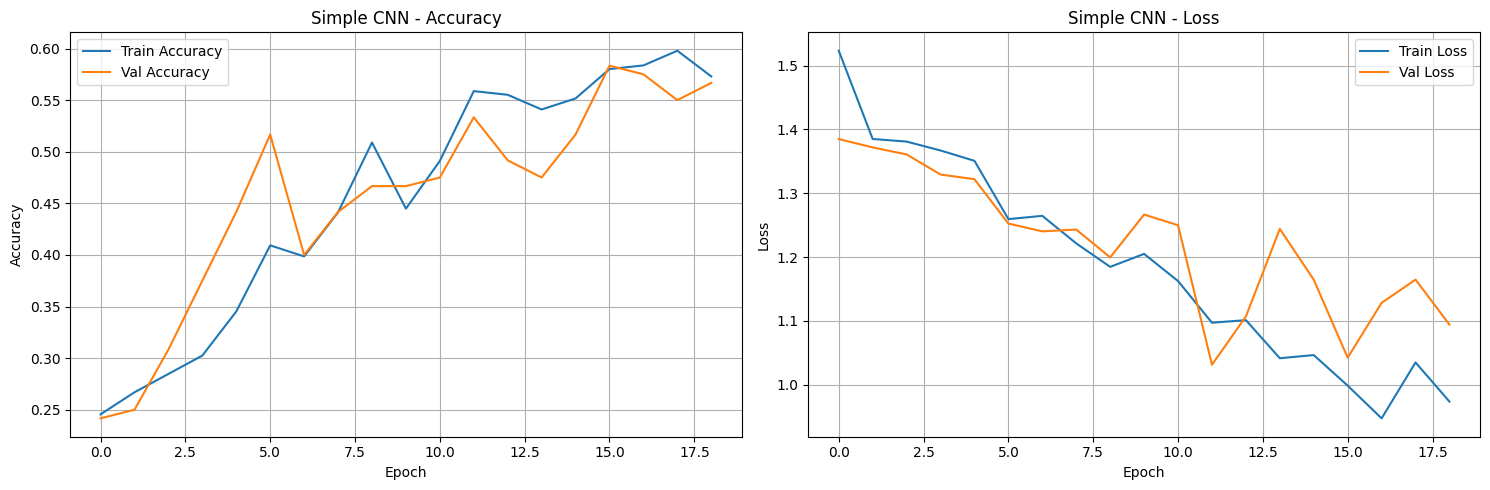

4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step


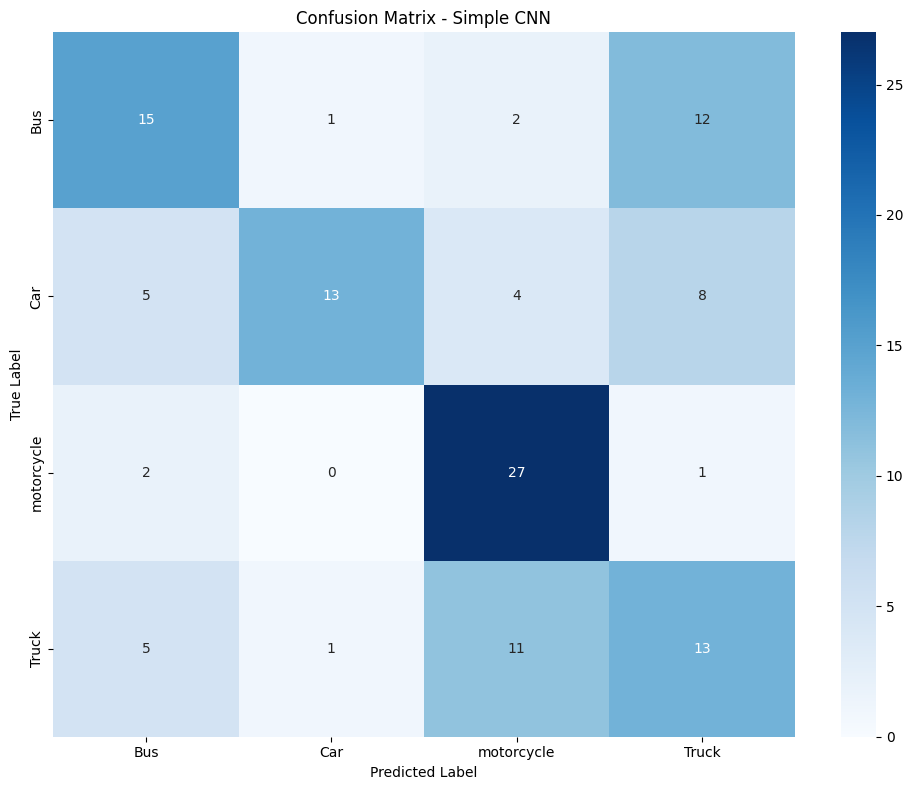


Classification Report для Simple CNN:
              precision    recall  f1-score   support

         Bus       0.56      0.50      0.53        30
         Car       0.87      0.43      0.58        30
  motorcycle       0.61      0.90      0.73        30
       Truck       0.38      0.43      0.41        30

    accuracy                           0.57       120
   macro avg       0.60      0.57      0.56       120
weighted avg       0.60      0.57      0.56       120


ЭКСПЕРИМЕНТ 2: Глубокая CNN с BatchNormalization


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 128, 128, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 64, 64, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_4 (Activation)            │ (None, 32, 32, 128)         │              

 Total params: 8,679,716 (33.11 MB)

 Trainable params: 8,678,308 (33.11 MB)

 Non-trainable params: 1,408 (5.50 KB)


Обучение модели: Deep CNN

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 49s 4s/step - accuracy: 0.3203 - loss: 2.0299 - val_accuracy: 0.2417 - val_loss: 1.4844 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.3772 - loss: 1.4804 - val_accuracy: 0.2500 - val_loss: 1.4485 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.4128 - loss: 1.3916 - val_accuracy: 0.2500 - val_loss: 1.4358 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.4270 - loss: 1.3053 - val_accuracy: 0.2500 - val_loss: 1.5535 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.4840 - loss: 1.2963 - val_accuracy: 0.2500 - val_loss: 1.6327 - learning_rate: 0.0010
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5114 - loss: 1.2282
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
9/9 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.4875 - loss: 1.2825 - va

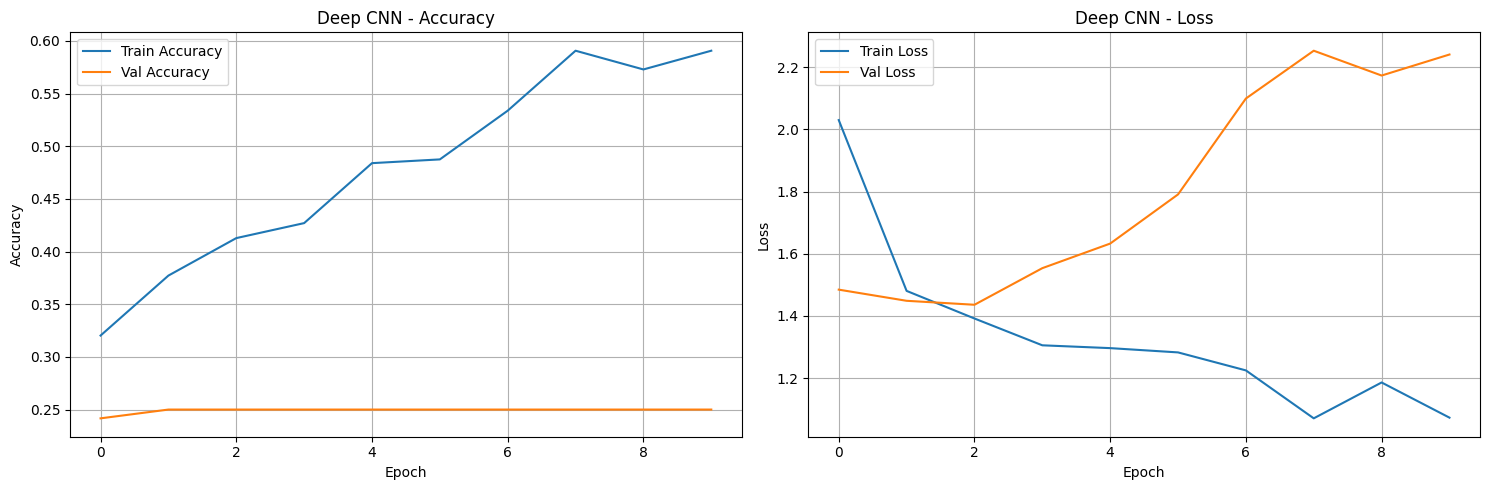

4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step


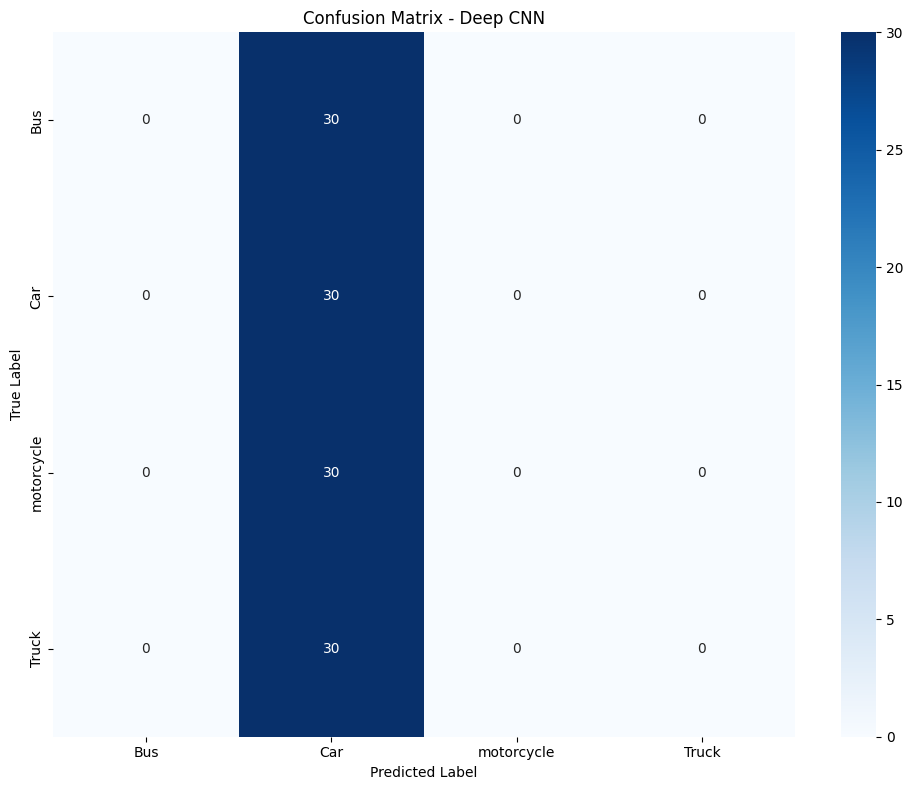


Classification Report для Deep CNN:
              precision    recall  f1-score   support

         Bus       0.00      0.00      0.00        30
         Car       0.25      1.00      0.40        30
  motorcycle       0.00      0.00      0.00        30
       Truck       0.00      0.00      0.00        30

    accuracy                           0.25       120
   macro avg       0.06      0.25      0.10       120
weighted avg       0.06      0.25      0.10       120


ЭКСПЕРИМЕНТ 3: Transfer Learning (MobileNetV2)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 4)                   │           1,028 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 1,535,044 (5.86 MB)

 Non-trainable params: 1,051,904 (4.01 MB)


Обучение модели: Transfer Learning

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 3s/step - accuracy: 0.4128 - loss: 1.4861 - val_accuracy: 0.7167 - val_loss: 0.7618 - learning_rate: 1.0000e-04
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.6228 - loss: 0.9651 - val_accuracy: 0.8000 - val_loss: 0.4787 - learning_rate: 1.0000e-04
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.7829 - loss: 0.6017 - val_accuracy: 0.8417 - val_loss: 0.3433 - learning_rate: 1.0000e-04
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.8007 - loss: 0.5069 - val_accuracy: 0.9250 - val_loss: 0.2176 - learning_rate: 1.0000e-04
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8114 - loss: 0.4453 - val_accuracy: 0.8750 - val_loss: 0.2572 - learning_rate: 1.0000e-04
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8683 - loss: 0.3508 - val_accuracy: 0.9250 - val_loss: 0.1833 - learning_rate: 1.0000e-04
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - a

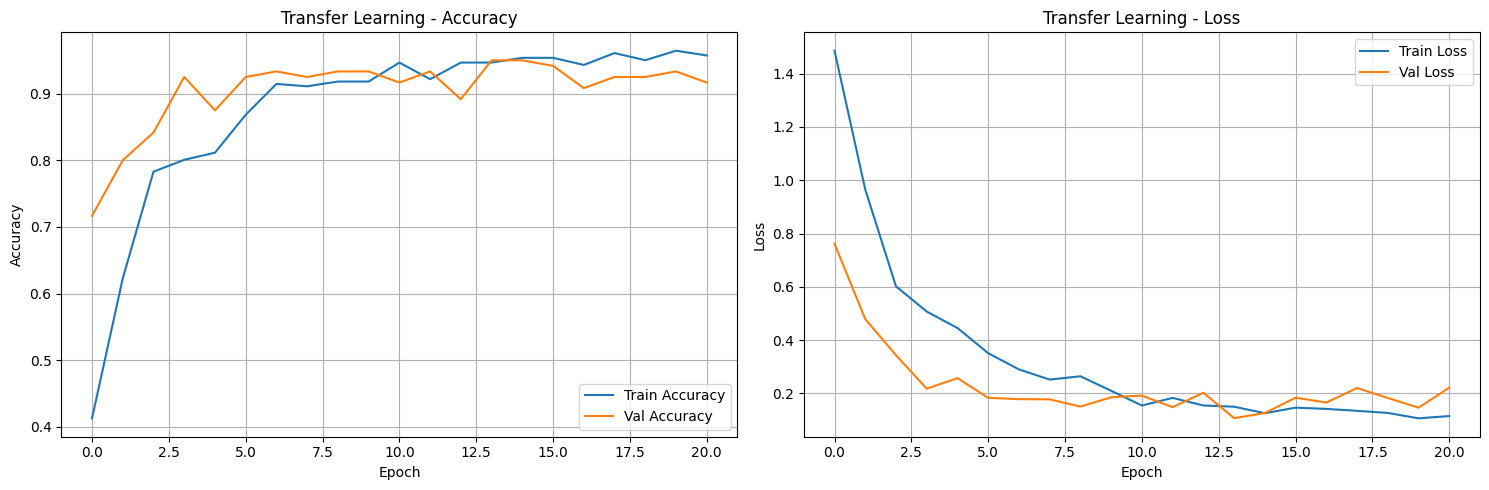

3/4 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   WARNING:tensorflow:6 out of the last 12 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000205BD878180> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step


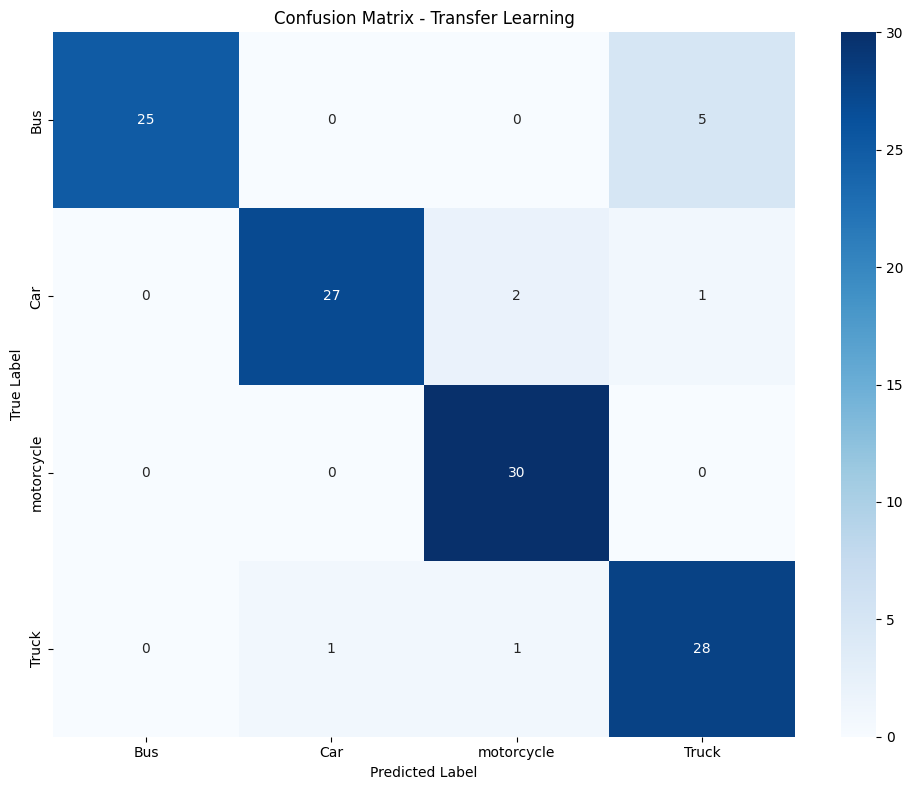


Classification Report для Transfer Learning:
              precision    recall  f1-score   support

         Bus       1.00      0.83      0.91        30
         Car       0.96      0.90      0.93        30
  motorcycle       0.91      1.00      0.95        30
       Truck       0.82      0.93      0.88        30

    accuracy                           0.92       120
   macro avg       0.92      0.92      0.92       120
weighted avg       0.92      0.92      0.92       120


ЭКСПЕРИМЕНТ 4: Улучшенная CNN


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 128, 128, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 128, 128, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_6 (Activation)            │ (None, 128, 128, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 128, 128, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 128, 128, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_7 (Activation)            │ (None, 128, 128, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 64, 64, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_8 (Activation)            │ (None, 64, 64, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 64, 64, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 64, 64, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_9 (Activation)            │ (None, 64, 64, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 32, 32, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 32, 32, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │              

 Total params: 1,414,980 (5.40 MB)

 Trainable params: 1,412,164 (5.39 MB)

 Non-trainable params: 2,816 (11.00 KB)


Обучение модели: Advanced CNN

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 72s 6s/step - accuracy: 0.2740 - loss: 2.2298 - val_accuracy: 0.1833 - val_loss: 1.4265 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.2847 - loss: 1.9252 - val_accuracy: 0.2500 - val_loss: 1.6295 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 53s 6s/step - accuracy: 0.3310 - loss: 1.7841 - val_accuracy: 0.2583 - val_loss: 1.5006 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 55s 6s/step - accuracy: 0.3772 - loss: 1.7357 - val_accuracy: 0.2333 - val_loss: 1.4028 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 56s 6s/step - accuracy: 0.3559 - loss: 1.6904 - val_accuracy: 0.2417 - val_loss: 1.4820 - learning_rate: 0.0010
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 80s 6s/step - accuracy: 0.3701 - loss: 1.6942 - val_accuracy: 0.2083 - val_loss: 1.4203 - learning_rate: 0.0010
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 55s 6s/step - accuracy: 0.3879 - loss: 1.584

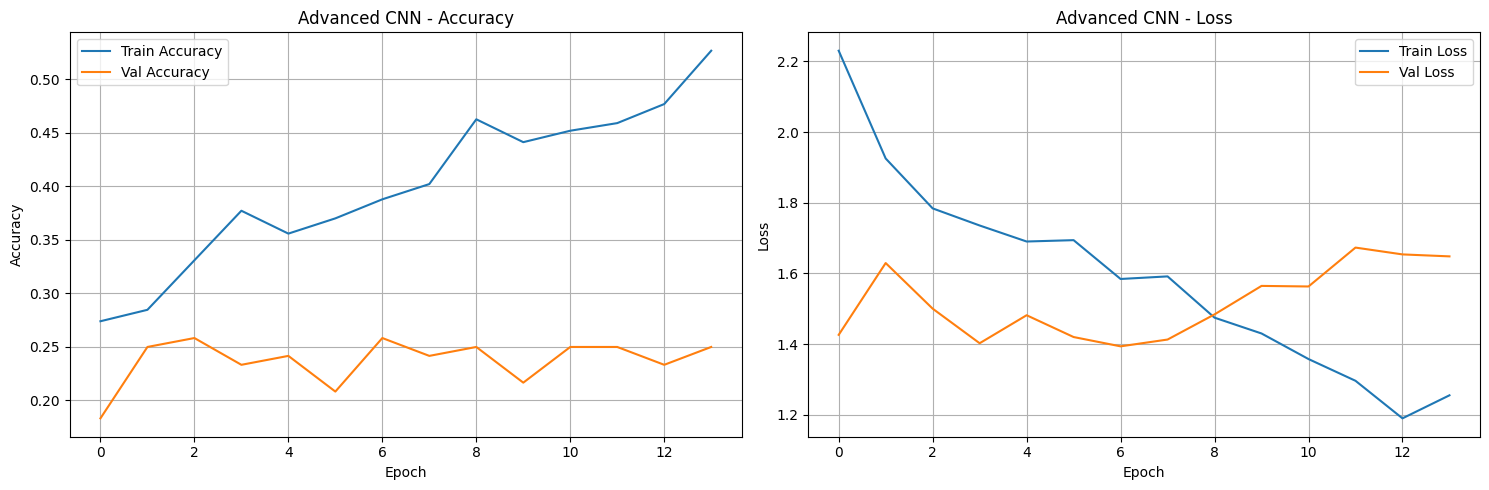

4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step


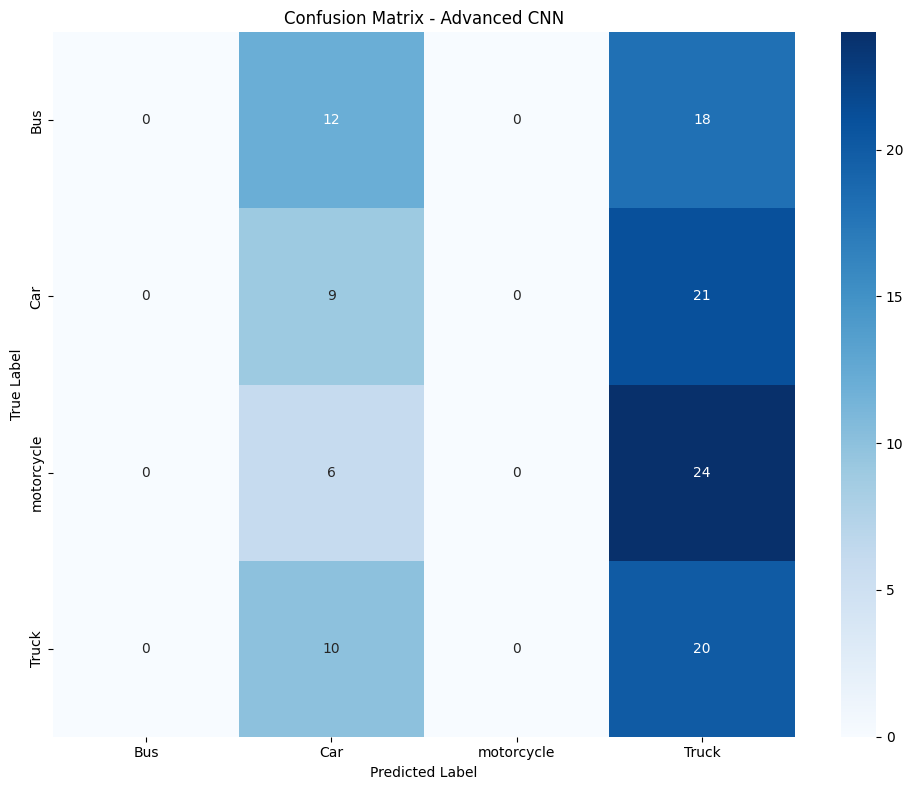


Classification Report для Advanced CNN:
              precision    recall  f1-score   support

         Bus       0.00      0.00      0.00        30
         Car       0.24      0.30      0.27        30
  motorcycle       0.00      0.00      0.00        30
       Truck       0.24      0.67      0.35        30

    accuracy                           0.24       120
   macro avg       0.12      0.24      0.16       120
weighted avg       0.12      0.24      0.16       120



In [21]:
input_shape = (*IMG_SIZE, 3)
results = {}

print(f"\nИспользуется {NUM_CLASSES} классов: {class_names}")
print(f"Входной размер изображения: {input_shape}\n")


if RUN_SIMPLE_CNN:
    print("\n" + "="*60)
    print("ЭКСПЕРИМЕНТ 1: Простая CNN")
    print("="*60)
    model1 = create_simple_cnn(input_shape, NUM_CLASSES)
    model1.summary()
    history1, acc1 = train_and_evaluate(model1, "Simple CNN", optimizer='adam', learning_rate=0.001)
    results['Simple CNN'] = acc1


if RUN_DEEP_CNN:
    print("\n" + "="*60)
    print("ЭКСПЕРИМЕНТ 2: Глубокая CNN с BatchNormalization")
    print("="*60)
    model2 = create_deep_cnn(input_shape, NUM_CLASSES)
    model2.summary()
    history2, acc2 = train_and_evaluate(model2, "Deep CNN", optimizer='adam', learning_rate=0.001)
    results['Deep CNN'] = acc2


if RUN_TRANSFER_LEARNING:
    print("\n" + "="*60)
    print("ЭКСПЕРИМЕНТ 3: Transfer Learning (MobileNetV2)")
    print("="*60)
    model3 = create_transfer_learning_model(input_shape, NUM_CLASSES)
    model3.summary()
    history3, acc3 = train_and_evaluate(model3, "Transfer Learning", optimizer='adam', learning_rate=0.0001)
    results['Transfer Learning'] = acc3


if RUN_ADVANCED_CNN:
    print("\n" + "="*60)
    print("ЭКСПЕРИМЕНТ 4: Улучшенная CNN")
    print("="*60)
    model4 = create_advanced_cnn(input_shape, NUM_CLASSES)
    model4.summary()
    history4, acc4 = train_and_evaluate(model4, "Advanced CNN", optimizer='adam', learning_rate=0.001)
    results['Advanced CNN'] = acc4


if RUN_DEEP_CNN_SGD:
    print("\n" + "="*60)
    print("ЭКСПЕРИМЕНТ 5: Deep CNN с SGD оптимизатором")
    print("="*60)
    model5 = create_deep_cnn(input_shape, NUM_CLASSES)
    history5, acc5 = train_and_evaluate(model5, "Deep CNN + SGD", optimizer='sgd', learning_rate=0.01)
    results['Deep CNN + SGD'] = acc5


             Model  Test Accuracy
Transfer Learning       0.908333
       Simple CNN       0.583333
     Advanced CNN       0.275000
         Deep CNN       0.250000


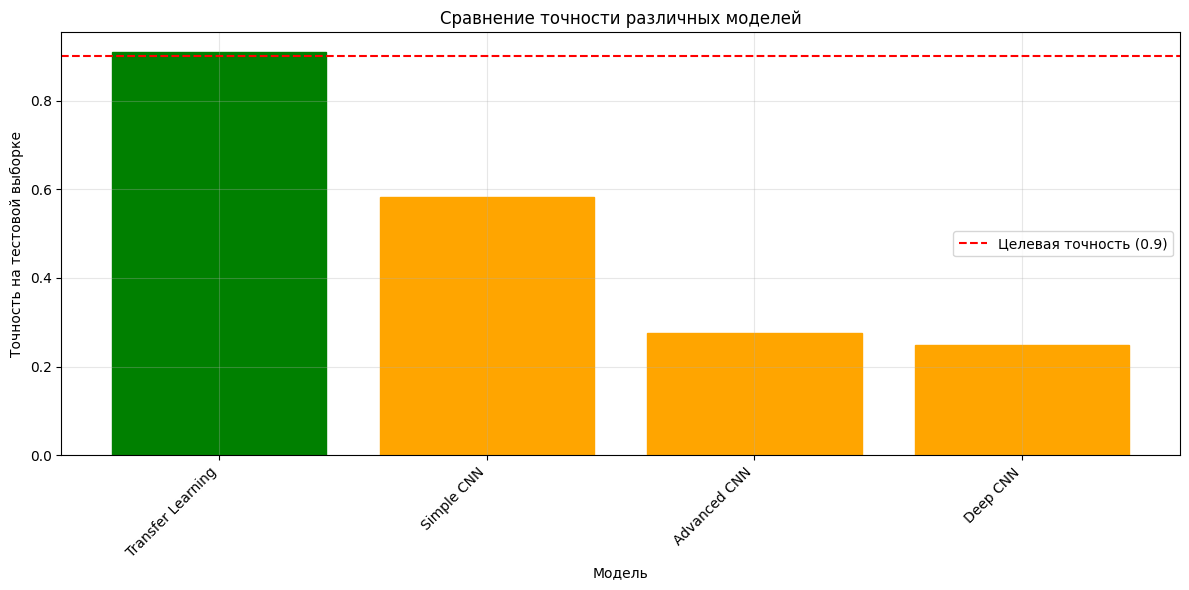


Лучшая модель: Transfer Learning
Точность: 0.9083

Цель достигнута! Точность превышает 0.9


In [22]:
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Test Accuracy'])
results_df = results_df.sort_values('Test Accuracy', ascending=False)
print("\n", results_df.to_string(index=False))


plt.figure(figsize=(12, 6))
bars = plt.bar(results_df['Model'], results_df['Test Accuracy'])
plt.axhline(y=0.9, color='r', linestyle='--', label='Целевая точность (0.9)')
plt.xlabel('Модель')
plt.ylabel('Точность на тестовой выборке')
plt.title('Сравнение точности различных моделей')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()


for i, bar in enumerate(bars):
    if results_df.iloc[i]['Test Accuracy'] >= 0.9:
        bar.set_color('green')
    else:
        bar.set_color('orange')

plt.show()


best_model_name = results_df.iloc[0]['Model']
best_accuracy = results_df.iloc[0]['Test Accuracy']
print(f"\nЛучшая модель: {best_model_name}")
print(f"Точность: {best_accuracy:.4f}")

if best_accuracy >= 0.9:
    print("\nЦель достигнута! Точность превышает 0.9")
else:
    print(f"\nЦель не достигнута. Требуется улучшение на {0.9 - best_accuracy:.4f}")
